In [1]:

# Cell 1 - Environment and Dataset Verification

from pathlib import Path
import sys
import pandas as pd
import numpy as np
import sklearn

print("SKIN DISORDER PREDICTION - PRCP-1027")
print("=" * 60)

# Step 1: Check Python and library versions
print("Python version:", sys.version.split()[0])
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Scikit-learn version:", sklearn.__version__)

# Step 2: Check current folder
print("\nCURRENT PROJECT FOLDER")
print("=" * 60)
print(Path.cwd())

# Step 3: Find dataset files
print("\nDATASET FILES")
print("=" * 60)

dataset_files = [
    file for file in Path.cwd().iterdir()
    if file.is_file()
    and file.suffix.lower() in [
        ".csv", ".xlsx", ".xls", ".data", ".zip"
    ]
]

if dataset_files:
    for file in sorted(dataset_files):
        size_kb = file.stat().st_size / 1024
        print(f"{file.name} - {size_kb:.2f} KB")
else:
    print("No dataset files found.")

print("\nCell 1 completed successfully.")


SKIN DISORDER PREDICTION - PRCP-1027
Python version: 3.14.3
Pandas version: 3.0.3
NumPy version: 2.4.2
Scikit-learn version: 1.9.0

CURRENT PROJECT FOLDER
E:\datamites project\Hardest capstone 4\Skin\Skin Disease

DATASET FILES
dataset_35_dermatology (1).csv - 26.13 KB

Cell 1 completed successfully.


In [2]:

# Cell 2 - Load and Inspect Dermatology Dataset

import pandas as pd
import numpy as np

# Step 1: Load the dataset
dataset_path = "dataset_35_dermatology (1).csv"

df = pd.read_csv(
    dataset_path,
    na_values=["?"]
)

print("DERMATOLOGY DATASET LOADED SUCCESSFULLY")
print("=" * 60)

# Step 2: Dataset dimensions
print("Dataset shape:", df.shape)
print("Total patients:", df.shape[0])
print("Total columns:", df.shape[1])

# Step 3: Separate feature names and target
target_column = "class"

feature_columns = [
    col for col in df.columns
    if col != target_column
]

print("\nCOLUMN INFORMATION")
print("=" * 60)
print("Input features:", len(feature_columns))
print("Target column:", target_column)
print("Number of disease classes:",
      df[target_column].nunique())

# Step 4: Display selected columns
print("\nFIRST FIVE PATIENT RECORDS")
print("=" * 60)

preview_columns = (
    feature_columns[:5]
    + ["Age", target_column]
)

display(df[preview_columns].head())

# Step 5: Check data types
print("\nDATA TYPES")
print("=" * 60)

print(df.dtypes.value_counts())

# Step 6: Identify missing values
print("\nMISSING VALUES")
print("=" * 60)

missing_counts = df.isna().sum()
print(missing_counts[missing_counts > 0])

# Step 7: Check target classes
print("\nAVAILABLE DISEASE CLASS LABELS")
print("=" * 60)

print(sorted(df[target_column].unique()))

print("\nCell 2 completed successfully.")


DERMATOLOGY DATASET LOADED SUCCESSFULLY
Dataset shape: (366, 35)
Total patients: 366
Total columns: 35

COLUMN INFORMATION
Input features: 34
Target column: class
Number of disease classes: 6

FIRST FIVE PATIENT RECORDS


,erythema,scaling,definite_borders,itching,koebner_phenomenon,Age,class
0,2,2,0,3,0,55.0,2
1,3,3,3,2,1,8.0,1
2,2,1,2,3,1,26.0,3
3,2,2,2,0,0,40.0,1
4,2,3,2,2,2,45.0,3



DATA TYPES
int64      34
float64     1
Name: count, dtype: int64

MISSING VALUES
Age    8
dtype: int64

AVAILABLE DISEASE CLASS LABELS
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]

Cell 2 completed successfully.


In [3]:

# Cell 3 - Dataset Quality and Class Distribution
# No model training

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("DERMATOLOGY DATASET QUALITY ASSESSMENT")
print("=" * 60)

# Step 1: Missing value analysis
missing_values = df.isna().sum()

print("\nMISSING VALUE ANALYSIS")
print("=" * 60)

print("Total missing values:", missing_values.sum())
print("Columns with missing values:",
      (missing_values > 0).sum())

display(
    missing_values[missing_values > 0]
    .to_frame(name="Missing_Count")
)

# Step 2: Duplicate records
print("\nDUPLICATE RECORD ANALYSIS")
print("=" * 60)

print("Duplicate full rows:", df.duplicated().sum())

print(
    "Duplicate feature rows:",
    df[feature_columns].duplicated().sum()
)

# Step 3: Disease class distribution
print("\nDISEASE CLASS DISTRIBUTION")
print("=" * 60)

class_counts = df["class"].value_counts().sort_index()

class_percentages = (
    df["class"].value_counts(normalize=True)
    .sort_index() * 100
)

class_distribution = pd.DataFrame({
    "Patient_Count": class_counts,
    "Percentage": class_percentages
})

display(class_distribution.round(2))

print(
    "Smallest class size:",
    class_counts.min()
)

print(
    "Largest class size:",
    class_counts.max()
)

# Step 4: Age analysis
print("\nPATIENT AGE ANALYSIS")
print("=" * 60)

print("Missing ages:", df["Age"].isna().sum())
print("Minimum age:", df["Age"].min())
print("Maximum age:", df["Age"].max())
print("Median age:", df["Age"].median())

# Step 5: Validate feature ranges
print("\nFEATURE RANGE VERIFICATION")
print("=" * 60)

graded_features = [
    col for col in feature_columns
    if col not in ["Age", "family_history"]
]

invalid_graded_values = (
    (~df[graded_features].isin([0, 1, 2, 3]))
    .sum().sum()
)

print(
    "Invalid values in 0-3 graded features:",
    invalid_graded_values
)

if "family_history" in df.columns:
    invalid_family_values = (
        ~df["family_history"].isin([0, 1])
    ).sum()

    print(
        "Invalid family history values:",
        invalid_family_values
    )

print("\nCell 3 completed successfully.")


DERMATOLOGY DATASET QUALITY ASSESSMENT

MISSING VALUE ANALYSIS
Total missing values: 8
Columns with missing values: 1


,Missing_Count
Age,8



DUPLICATE RECORD ANALYSIS
Duplicate full rows: 0
Duplicate feature rows: 0

DISEASE CLASS DISTRIBUTION


,Patient_Count,Percentage
class,,
1,112,30.60
2,61,16.67
3,72,19.67
4,49,13.39
5,52,14.21
6,20,5.46


Smallest class size: 20
Largest class size: 112

PATIENT AGE ANALYSIS
Missing ages: 8
Minimum age: 0.0
Maximum age: 75.0
Median age: 35.0

FEATURE RANGE VERIFICATION
Invalid values in 0-3 graded features: 0
Invalid family history values: 0

Cell 3 completed successfully.


In [4]:

# Cell 4 - Stratified Train-Test Split
# No model training or imputation

import pandas as pd
from sklearn.model_selection import train_test_split

# Step 1: Define features and target
X = df[feature_columns].copy()
y = df["class"].copy()

# Step 2: Stratified 80:20 split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("STRATIFIED TRAIN-TEST SPLIT")
print("=" * 60)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

# Step 3: Check class counts in each dataset
class_split = pd.DataFrame({
    "Original": y.value_counts().sort_index(),
    "Training": y_train.value_counts().sort_index(),
    "Testing": y_test.value_counts().sort_index()
})

print("\nDISEASE CLASS DISTRIBUTION")
print("=" * 60)

display(class_split)

# Step 4: Check missing ages in each split
print("\nMISSING AGE VALUES")
print("=" * 60)

print("Training missing ages:", X_train["Age"].isna().sum())
print("Testing missing ages:", X_test["Age"].isna().sum())

# Step 5: Check unusual age values
print("\nAGE ZERO CHECK")
print("=" * 60)

print("Patients with age 0:", (df["Age"] == 0).sum())

# Step 6: Verify data integrity
overlapping_records = X_train.index.intersection(X_test.index)

print("\nDATA INTEGRITY VERIFICATION")
print("=" * 60)

print("Overlapping patient rows:", len(overlapping_records))
print("Total records:", len(X_train) + len(X_test))
print("Input features:", X_train.shape[1])

assert len(overlapping_records) == 0
assert len(X_train) + len(X_test) == len(df)
assert X_train.shape[1] == 34
assert y_train.nunique() == 6
assert y_test.nunique() == 6

print("\nTrain-test split verification: PASSED")
print("Cell 4 completed successfully.")


STRATIFIED TRAIN-TEST SPLIT
Training features: (292, 34)
Testing features: (74, 34)
Training target: (292,)
Testing target: (74,)

DISEASE CLASS DISTRIBUTION


,Original,Training,Testing
class,,,
1,112,89,23
2,61,49,12
3,72,57,15
4,49,39,10
5,52,42,10
6,20,16,4



MISSING AGE VALUES
Training missing ages: 5
Testing missing ages: 3

AGE ZERO CHECK
Patients with age 0: 1

DATA INTEGRITY VERIFICATION
Overlapping patient rows: 0
Total records: 366
Input features: 34

Train-test split verification: PASSED
Cell 4 completed successfully.


DISEASE-BASED FEATURE ANALYSIS

FIRST 8 FEATURES - CLASS MEANS


,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement
class,,,,,,,,
1,2.30,2.19,2.11,0.94,0.66,0.00,0.04,0.00
2,2.27,2.08,0.94,1.57,0.00,0.00,0.02,0.00
3,2.07,1.65,2.14,2.25,1.35,2.25,0.00,1.95
4,1.87,1.51,1.15,0.56,1.18,0.00,0.00,0.00
5,1.43,1.12,0.90,2.05,0.00,0.00,0.19,0.00
6,2.00,1.75,1.19,0.50,0.00,0.00,2.25,0.00



TOP 10 FEATURES BY CLASS MEAN DIFFERENCES


,Class_Separation_Score
perifollicular_parakeratosis,1.5868
follicular_horn_plug,1.5131
follicular_papules,1.4255
fibrosis_of_the_papillary_dermis,0.9978
band-like_infiltrate,0.9120
vacuolisation_and_damage_of_basal_layer,0.9085
saw-tooth_appearance_of_retes,0.8955
melanin_incontinence,0.8907
polygonal_papules,0.8822
focal_hypergranulosis,0.8791



AGE STATISTICS BY DISEASE CLASS


,count,median,min,max
class,,,,
1,88,37.0,0.0,75.0
2,49,33.0,10.0,70.0
3,56,42.0,18.0,65.0
4,38,35.0,16.0,70.0
5,40,36.0,16.0,70.0
6,16,8.0,7.0,22.0


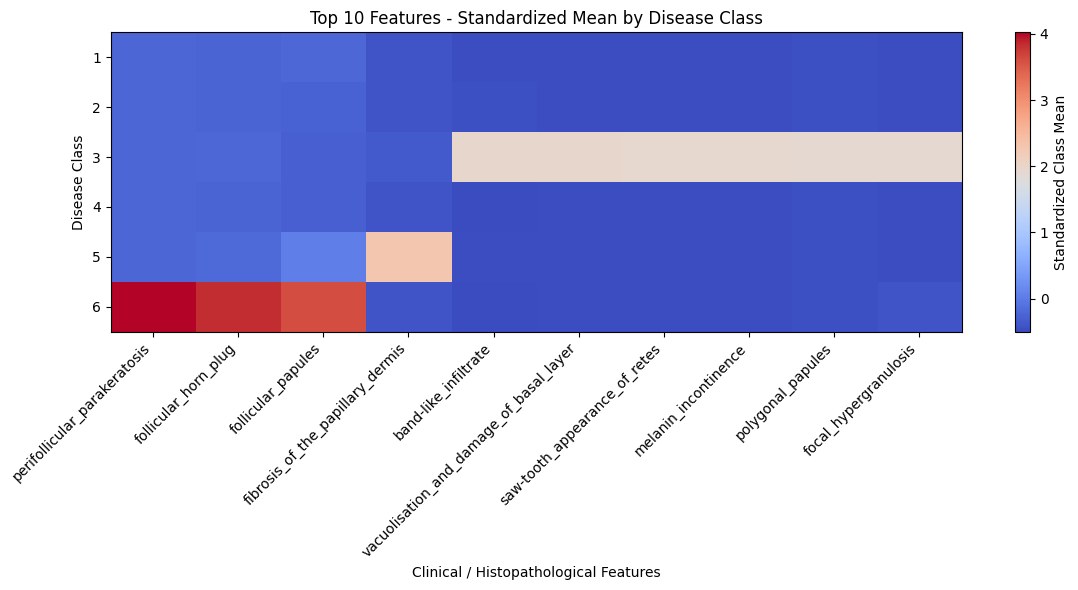


Cell 5 completed successfully.


In [5]:

# Cell 5 - Disease-Based Feature Analysis
# Training data only - no model training

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Step 1: Prepare training data for EDA
train_eda = X_train.copy()
train_eda["class"] = y_train

# Step 2: Calculate mean feature values by disease class
class_feature_means = (
    train_eda.groupby("class")[feature_columns].mean()
)

print("DISEASE-BASED FEATURE ANALYSIS")
print("=" * 60)

print("\nFIRST 8 FEATURES - CLASS MEANS")
print("=" * 60)

display(class_feature_means.iloc[:, :8].round(2))

# Step 3: Measure variation of class means
# Relative to each feature's overall training variation
feature_std = X_train[feature_columns].std()

between_class_spread = (
    class_feature_means.std(axis=0, ddof=0)
)

separation_score = (
    between_class_spread /
    feature_std.replace(0, np.nan)
)

feature_ranking = (
    separation_score
    .sort_values(ascending=False)
    .head(10)
    .to_frame(name="Class_Separation_Score")
)

print("\nTOP 10 FEATURES BY CLASS MEAN DIFFERENCES")
print("=" * 60)

display(feature_ranking.round(4))

# Step 4: Analyze age distribution by class
print("\nAGE STATISTICS BY DISEASE CLASS")
print("=" * 60)

age_summary = train_eda.groupby("class")["Age"].agg(
    ["count", "median", "min", "max"]
)

display(age_summary.round(2))

# Step 5: Visualize standardized class means
top_features = feature_ranking.index.tolist()

training_means = X_train[top_features].mean()
training_std = X_train[top_features].std()

standardized_means = (
    (class_feature_means[top_features] - training_means)
    / training_std.replace(0, np.nan)
)

fig, ax = plt.subplots(figsize=(12, 6))

im = ax.imshow(
    standardized_means.to_numpy(),
    aspect="auto",
    cmap="coolwarm"
)

ax.set_xticks(range(len(top_features)))
ax.set_xticklabels(
    top_features,
    rotation=45,
    ha="right"
)

ax.set_yticks(range(len(class_feature_means)))
ax.set_yticklabels(class_feature_means.index)

ax.set_xlabel("Clinical / Histopathological Features")
ax.set_ylabel("Disease Class")
ax.set_title(
    "Top 10 Features - Standardized Mean by Disease Class"
)

fig.colorbar(
    im,
    ax=ax,
    label="Standardized Class Mean"
)

plt.tight_layout()
plt.show()

print("\nCell 5 completed successfully.")


In [6]:

# Cell 6 - Preprocessing and Cross-Validation Setup
# No model training in this cell

import pandas as pd

from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

# Step 1: Define stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Step 2: Define model pipelines
models = {
    "Dummy Classifier": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", DummyClassifier(
            strategy="most_frequent"
        ))
    ]),

    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "Gaussian Naive Bayes": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", GaussianNB())
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", RandomForestClassifier(
            n_estimators=150,
            min_samples_leaf=2,
            class_weight="balanced_subsample",
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "Support Vector Machine": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", SVC(
            kernel="rbf",
            class_weight="balanced",
            random_state=42
        ))
    ])
}

# Step 3: Display models
print("MACHINE LEARNING MODEL SETUP")
print("=" * 60)

for i, name in enumerate(models.keys(), 1):
    print(f"{i}. {name}")

# Step 4: Verify class distribution in each CV fold
print("\n5-FOLD STRATIFIED CROSS-VALIDATION")
print("=" * 60)

fold_details = []

for fold_number, (train_idx, val_idx) in enumerate(
    cv.split(X_train, y_train), start=1
):
    fold_y_train = y_train.iloc[train_idx]
    fold_y_val = y_train.iloc[val_idx]

    fold_details.append({
        "Fold": fold_number,
        "Training_Patients": len(train_idx),
        "Validation_Patients": len(val_idx),
        "Training_Classes": fold_y_train.nunique(),
        "Validation_Classes": fold_y_val.nunique(),
        "Class_6_Validation": int(
            (fold_y_val == 6).sum()
        )
    })

cv_summary = pd.DataFrame(fold_details)
display(cv_summary)

# Step 5: Final setup verification
print("\nSETUP VERIFICATION")
print("=" * 60)

print("Number of models:", len(models))
print("Number of CV folds:", cv.get_n_splits())
print("Training patients:", len(X_train))
print("Reserved test patients:", len(X_test))
print("Feature count:", X_train.shape[1])

assert len(models) == 5
assert len(cv_summary) == 5
assert (cv_summary["Validation_Classes"] == 6).all()
assert X_train.shape[1] == 34

print("\nCell 6 setup verification: PASSED")


MACHINE LEARNING MODEL SETUP
1. Dummy Classifier
2. Logistic Regression
3. Gaussian Naive Bayes
4. Random Forest
5. Support Vector Machine

5-FOLD STRATIFIED CROSS-VALIDATION


,Fold,Training_Patients,Validation_Patients,Training_Classes,Validation_Classes,Class_6_Validation
0,1,233,59,6,6,3
1,2,233,59,6,6,4
2,3,234,58,6,6,3
3,4,234,58,6,6,3
4,5,234,58,6,6,3



SETUP VERIFICATION
Number of models: 5
Number of CV folds: 5
Training patients: 292
Reserved test patients: 74
Feature count: 34

Cell 6 setup verification: PASSED


In [7]:

# Cell 7 - Model Training and Cross-Validation
# Five models evaluated using stratified 5-fold CV

import time
import numpy as np
import pandas as pd

from sklearn.model_selection import cross_validate

print("SKIN DISORDER PREDICTION")
print("MODEL TRAINING AND CROSS-VALIDATION")
print("=" * 65)

# Step 1: Define evaluation metrics
scoring = {
    "Accuracy": "accuracy",
    "Macro_F1": "f1_macro",
    "Balanced_Accuracy": "balanced_accuracy",
    "Weighted_F1": "f1_weighted"
}

# Step 2: Create result storage
cv_results = []

# Step 3: Evaluate each model
for model_name, pipeline in models.items():

    print("\n" + "=" * 65)
    print("MODEL:", model_name)
    print("=" * 65)

    start_time = time.perf_counter()

    scores = cross_validate(
        estimator=pipeline,
        X=X_train,
        y=y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
        error_score="raise"
    )

    total_time = time.perf_counter() - start_time

    # Store results
    cv_results.append({
        "Model": model_name,
        "Accuracy": scores["test_Accuracy"].mean(),
        "Macro_F1": scores["test_Macro_F1"].mean(),
        "Macro_F1_Std": scores["test_Macro_F1"].std(),
        "Balanced_Accuracy": (
            scores["test_Balanced_Accuracy"].mean()
        ),
        "Weighted_F1": scores["test_Weighted_F1"].mean(),
        "Total_Time_Sec": total_time
    })

    print(
        "Accuracy:",
        round(scores["test_Accuracy"].mean(), 4)
    )

    print(
        "Macro F1:",
        round(scores["test_Macro_F1"].mean(), 4)
    )

    print(
        "Balanced Accuracy:",
        round(
            scores["test_Balanced_Accuracy"].mean(), 4
        )
    )

    print(
        "Fold Macro F1 scores:",
        np.round(scores["test_Macro_F1"], 4)
    )

    print(
        f"Total execution time: {total_time:.2f} seconds"
    )

# Step 4: Create model comparison table
model_comparison = pd.DataFrame(cv_results)

model_comparison = (
    model_comparison
    .sort_values("Macro_F1", ascending=False)
    .reset_index(drop=True)
)

print("\n" + "=" * 65)
print("FINAL CROSS-VALIDATION MODEL COMPARISON")
print("=" * 65)

display(model_comparison.round(4))

# Step 5: Identify leading model
best_model_name = model_comparison.iloc[0]["Model"]

print("\nBEST MODEL BY MEAN MACRO F1")
print("=" * 65)
print(best_model_name)

# Step 6: Confirm test set remains untouched
print("\nTEST DATA STATUS")
print("=" * 65)

print("Reserved test patients:", len(X_test))
print("Test set used for training: NO")
print("Test set used for model selection: NO")

print("\nCell 7 completed successfully.")


SKIN DISORDER PREDICTION
MODEL TRAINING AND CROSS-VALIDATION

MODEL: Dummy Classifier
Accuracy: 0.3048
Macro F1: 0.0779
Balanced Accuracy: 0.1667
Fold Macro F1 scores: [0.0779 0.0779 0.0756 0.0789 0.0789]
Total execution time: 0.11 seconds

MODEL: Logistic Regression
Accuracy: 0.9794
Macro F1: 0.9768
Balanced Accuracy: 0.9774
Fold Macro F1 scores: [1.     0.9804 0.981  0.9595 0.963 ]
Total execution time: 0.30 seconds

MODEL: Gaussian Naive Bayes
Accuracy: 0.8972
Macro F1: 0.8776
Balanced Accuracy: 0.8978
Fold Macro F1 scores: [0.9013 0.8703 0.8831 0.8283 0.9048]
Total execution time: 0.22 seconds

MODEL: Random Forest
Accuracy: 0.976
Macro F1: 0.9704
Balanced Accuracy: 0.9652
Fold Macro F1 scores: [0.9677 0.9804 0.9429 1.     0.961 ]
Total execution time: 3.36 seconds

MODEL: Support Vector Machine
Accuracy: 0.9794
Macro F1: 0.9768
Balanced Accuracy: 0.9774
Fold Macro F1 scores: [1.     0.9804 0.981  0.9595 0.963 ]
Total execution time: 0.14 seconds

FINAL CROSS-VALIDATION MODEL COMPA

,Model,Accuracy,Macro_F1,Macro_F1_Std,Balanced_Accuracy,Weighted_F1,Total_Time_Sec
0,Logistic Regression,0.9794,0.9768,0.0145,0.9774,0.9793,0.2954
1,Support Vector Machine,0.9794,0.9768,0.0145,0.9774,0.9793,0.1400
2,Random Forest,0.9760,0.9704,0.0191,0.9652,0.9755,3.3554
3,Gaussian Naive Bayes,0.8972,0.8776,0.0276,0.8978,0.8862,0.2243
4,Dummy Classifier,0.3048,0.0779,0.0012,0.1667,0.1424,0.1137



BEST MODEL BY MEAN MACRO F1
Logistic Regression

TEST DATA STATUS
Reserved test patients: 74
Test set used for training: NO
Test set used for model selection: NO

Cell 7 completed successfully.


In [8]:

# Cell 8 - Detailed Cross-Validation Evaluation
# Top two models: Logistic Regression and SVM

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    f1_score,
    balanced_accuracy_score
)

print("DETAILED MODEL EVALUATION")
print("=" * 65)

# Step 1: Select top two models
top_models = {
    "Logistic Regression": models["Logistic Regression"],
    "Support Vector Machine": models["Support Vector Machine"]
}

class_labels = sorted(y_train.unique())

oof_predictions = {}
detailed_results = []

# Step 2: Generate out-of-fold predictions
for name, pipeline in top_models.items():

    print("\n" + "=" * 65)
    print("MODEL:", name)
    print("=" * 65)

    predictions = cross_val_predict(
        estimator=pipeline,
        X=X_train,
        y=y_train,
        cv=cv,
        n_jobs=1
    )

    oof_predictions[name] = predictions

    # Overall metrics
    detailed_results.append({
        "Model": name,
        "OOF_Accuracy": accuracy_score(y_train, predictions),
        "OOF_Macro_F1": f1_score(
            y_train, predictions, average="macro"
        ),
        "OOF_Balanced_Accuracy": balanced_accuracy_score(
            y_train, predictions
        ),
        "Correct_Predictions": int(
            (y_train.to_numpy() == predictions).sum()
        )
    })

    # Per-class evaluation
    print("\nCLASSIFICATION REPORT")
    print(
        classification_report(
            y_train,
            predictions,
            labels=class_labels,
            digits=4,
            zero_division=0
        )
    )

    # Confusion matrix
    cm = confusion_matrix(
        y_train,
        predictions,
        labels=class_labels
    )

    print("\nCONFUSION MATRIX")
    display(
        pd.DataFrame(
            cm,
            index=[f"Actual {i}" for i in class_labels],
            columns=[f"Predicted {i}" for i in class_labels]
        )
    )

# Step 3: Compare both models
print("\nTOP TWO MODELS - OUT-OF-FOLD COMPARISON")
print("=" * 65)

detailed_comparison = pd.DataFrame(detailed_results)

display(detailed_comparison.round(4))

# Step 4: Check whether predictions are identical
agreement = np.mean(
    oof_predictions["Logistic Regression"]
    == oof_predictions["Support Vector Machine"]
)

print("\nMODEL AGREEMENT")
print("=" * 65)

print(f"Prediction agreement: {agreement * 100:.2f}%")

print(
    "Different predictions:",
    np.sum(
        oof_predictions["Logistic Regression"]
        != oof_predictions["Support Vector Machine"]
    )
)

print("\nReserved test set remains untouched:", len(X_test))
print("Cell 8 completed successfully.")


DETAILED MODEL EVALUATION

MODEL: Logistic Regression

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           1     1.0000    1.0000    1.0000        89
           2     0.9574    0.9184    0.9375        49
           3     1.0000    1.0000    1.0000        57
           4     0.9024    0.9487    0.9250        39
           5     1.0000    1.0000    1.0000        42
           6     1.0000    1.0000    1.0000        16

    accuracy                         0.9795       292
   macro avg     0.9766    0.9778    0.9771       292
weighted avg     0.9798    0.9795    0.9795       292


CONFUSION MATRIX


,Predicted 1,Predicted 2,Predicted 3,Predicted 4,Predicted 5,Predicted 6
Actual 1,89,0,0,0,0,0
Actual 2,0,45,0,4,0,0
Actual 3,0,0,57,0,0,0
Actual 4,0,2,0,37,0,0
Actual 5,0,0,0,0,42,0
Actual 6,0,0,0,0,0,16



MODEL: Support Vector Machine

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           1     1.0000    1.0000    1.0000        89
           2     0.9574    0.9184    0.9375        49
           3     1.0000    1.0000    1.0000        57
           4     0.9024    0.9487    0.9250        39
           5     1.0000    1.0000    1.0000        42
           6     1.0000    1.0000    1.0000        16

    accuracy                         0.9795       292
   macro avg     0.9766    0.9778    0.9771       292
weighted avg     0.9798    0.9795    0.9795       292


CONFUSION MATRIX


,Predicted 1,Predicted 2,Predicted 3,Predicted 4,Predicted 5,Predicted 6
Actual 1,89,0,0,0,0,0
Actual 2,0,45,0,4,0,0
Actual 3,0,0,57,0,0,0
Actual 4,0,2,0,37,0,0
Actual 5,0,0,0,0,42,0
Actual 6,0,0,0,0,0,16



TOP TWO MODELS - OUT-OF-FOLD COMPARISON


,Model,OOF_Accuracy,OOF_Macro_F1,OOF_Balanced_Accuracy,Correct_Predictions
0,Logistic Regression,0.9795,0.9771,0.9778,286
1,Support Vector Machine,0.9795,0.9771,0.9778,286



MODEL AGREEMENT
Prediction agreement: 100.00%
Different predictions: 0

Reserved test set remains untouched: 74
Cell 8 completed successfully.


In [9]:

# Cell 9 - Clinical-Only vs Full-Feature Model
# No test data used

import numpy as np
import pandas as pd

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    recall_score,
    classification_report,
    confusion_matrix
)

# Step 1: Select clinical attributes
# The first 11 features are clinical measurements
# including family_history; Age is the 12th.

clinical_features = feature_columns[:11] + ["Age"]

assert len(clinical_features) == 12
assert len(set(clinical_features)) == 12
assert "family_history" in clinical_features
assert "Age" in clinical_features

print("CLINICAL-ONLY MODEL EXPERIMENT")
print("=" * 65)

print("\nCLINICAL FEATURES")
for i, feature in enumerate(clinical_features, start=1):
    print(f"{i}. {feature}")

print("\nNumber of clinical features:", len(clinical_features))
print("Number of full-model features:", len(feature_columns))

# Step 2: Obtain clinical-only out-of-fold predictions
# Existing pipeline handles missing ages and scaling

clinical_oof_pred = cross_val_predict(
    estimator=models["Logistic Regression"],
    X=X_train[clinical_features],
    y=y_train,
    cv=cv,
    n_jobs=1
)

# Step 3: Reuse full-model predictions from Cell 8
full_oof_pred = oof_predictions["Logistic Regression"]

# Step 4: Compare performance
comparison_rows = []

for name, predictions, n_features in [
    ("Clinical Only", clinical_oof_pred, 12),
    ("Full Features", full_oof_pred, 34)
]:
    comparison_rows.append({
        "Model": name,
        "Features": n_features,
        "Accuracy": accuracy_score(y_train, predictions),
        "Macro_F1": f1_score(
            y_train, predictions, average="macro"
        ),
        "Balanced_Accuracy": balanced_accuracy_score(
            y_train, predictions
        ),
        "Correct": int(
            (y_train.to_numpy() == predictions).sum()
        )
    })

clinical_comparison = pd.DataFrame(comparison_rows)

print("\nCLINICAL VS FULL MODEL COMPARISON")
print("=" * 65)

display(clinical_comparison.round(4))

# Step 5: Per-class recall comparison
class_labels = sorted(y_train.unique())

clinical_recall = recall_score(
    y_train,
    clinical_oof_pred,
    labels=class_labels,
    average=None,
    zero_division=0
)

full_recall = recall_score(
    y_train,
    full_oof_pred,
    labels=class_labels,
    average=None,
    zero_division=0
)

recall_comparison = pd.DataFrame({
    "Disease_Class": class_labels,
    "Clinical_Recall": clinical_recall,
    "Full_Model_Recall": full_recall
})

print("\nPER-CLASS RECALL COMPARISON")
print("=" * 65)

display(recall_comparison.round(4))

# Step 6: Clinical-only classification report
print("\nCLINICAL-ONLY CLASSIFICATION REPORT")
print("=" * 65)

print(
    classification_report(
        y_train,
        clinical_oof_pred,
        labels=class_labels,
        digits=4,
        zero_division=0
    )
)

# Step 7: Clinical-only confusion matrix
print("\nCLINICAL-ONLY CONFUSION MATRIX")
print("=" * 65)

clinical_cm = confusion_matrix(
    y_train,
    clinical_oof_pred,
    labels=class_labels
)

display(
    pd.DataFrame(
        clinical_cm,
        index=[f"Actual {c}" for c in class_labels],
        columns=[f"Predicted {c}" for c in class_labels]
    )
)

print("\nTEST DATA VERIFICATION")
print("=" * 65)
print("Reserved test patients:", len(X_test))
print("Test data used: NO")

print("\nCell 9 completed successfully.")


CLINICAL-ONLY MODEL EXPERIMENT

CLINICAL FEATURES
1. erythema
2. scaling
3. definite_borders
4. itching
5. koebner_phenomenon
6. polygonal_papules
7. follicular_papules
8. oral_mucosal_involvement
9. knee_and_elbow_involvement
10. scalp_involvement
11. family_history
12. Age

Number of clinical features: 12
Number of full-model features: 34

CLINICAL VS FULL MODEL COMPARISON


,Model,Features,Accuracy,Macro_F1,Balanced_Accuracy,Correct
0,Clinical Only,12,0.8767,0.8733,0.8747,256
1,Full Features,34,0.9795,0.9771,0.9778,286



PER-CLASS RECALL COMPARISON


,Disease_Class,Clinical_Recall,Full_Model_Recall
0,1,0.9326,1.0000
1,2,0.7959,0.9184
2,3,0.9649,1.0000
3,4,0.7692,0.9487
4,5,0.7857,1.0000
5,6,1.0000,1.0000



CLINICAL-ONLY CLASSIFICATION REPORT
              precision    recall  f1-score   support

           1     0.9881    0.9326    0.9595        89
           2     0.7091    0.7959    0.7500        49
           3     1.0000    0.9649    0.9821        57
           4     0.8108    0.7692    0.7895        39
           5     0.7333    0.7857    0.7586        42
           6     1.0000    1.0000    1.0000        16

    accuracy                         0.8767       292
   macro avg     0.8736    0.8747    0.8733       292
weighted avg     0.8839    0.8767    0.8794       292


CLINICAL-ONLY CONFUSION MATRIX


,Predicted 1,Predicted 2,Predicted 3,Predicted 4,Predicted 5,Predicted 6
Actual 1,83,3,0,3,0,0
Actual 2,1,39,0,0,9,0
Actual 3,0,0,55,2,0,0
Actual 4,0,6,0,30,3,0
Actual 5,0,7,0,2,33,0
Actual 6,0,0,0,0,0,16



TEST DATA VERIFICATION
Reserved test patients: 74
Test data used: NO

Cell 9 completed successfully.


In [10]:

# Cell 10 - Final Logistic Regression Test Evaluation
# Train on all training patients; evaluate held-out test once

import time
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

print("FINAL MODEL - LOGISTIC REGRESSION")
print("=" * 65)

# Step 1: Clone the selected model pipeline
# Includes median imputation and StandardScaler
final_model = clone(models["Logistic Regression"])

# Step 2: Fit using all 292 training patients
start_time = time.perf_counter()

final_model.fit(X_train, y_train)

training_time = time.perf_counter() - start_time

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))
print("Input features:", X_train.shape[1])
print(f"Training time: {training_time:.4f} seconds")

# Step 3: Predict on the held-out test set
final_test_pred = final_model.predict(X_test)

# Step 4: Calculate final test metrics
final_test_metrics = {
    "Accuracy": accuracy_score(
        y_test, final_test_pred
    ),
    "Macro_F1": f1_score(
        y_test, final_test_pred, average="macro"
    ),
    "Balanced_Accuracy": balanced_accuracy_score(
        y_test, final_test_pred
    ),
    "Weighted_F1": f1_score(
        y_test, final_test_pred, average="weighted"
    )
}

print("\nFINAL HELD-OUT TEST RESULTS")
print("=" * 65)

display(
    pd.DataFrame([final_test_metrics]).round(4)
)

# Step 5: Detailed classification report
class_labels = sorted(y_train.unique())

print("\nTEST CLASSIFICATION REPORT")
print("=" * 65)

print(
    classification_report(
        y_test,
        final_test_pred,
        labels=class_labels,
        digits=4,
        zero_division=0
    )
)

# Step 6: Test confusion matrix
test_cm = confusion_matrix(
    y_test,
    final_test_pred,
    labels=class_labels
)

print("\nTEST CONFUSION MATRIX")
print("=" * 65)

display(
    pd.DataFrame(
        test_cm,
        index=[f"Actual {c}" for c in class_labels],
        columns=[f"Predicted {c}" for c in class_labels]
    )
)

# Step 7: Summarize correct and incorrect predictions
correct_predictions = int(
    (y_test.to_numpy() == final_test_pred).sum()
)

print("\nFINAL TEST SUMMARY")
print("=" * 65)

print("Correct predictions:", correct_predictions)
print(
    "Incorrect predictions:",
    len(y_test) - correct_predictions
)

print("Class 6 test patients:", int((y_test == 6).sum()))
print("\nCell 10 completed successfully.")


FINAL MODEL - LOGISTIC REGRESSION
Training samples: 292
Test samples: 74
Input features: 34
Training time: 0.0279 seconds

FINAL HELD-OUT TEST RESULTS


,Accuracy,Macro_F1,Balanced_Accuracy,Weighted_F1
0,0.9595,0.9574,0.9611,0.9606



TEST CLASSIFICATION REPORT
              precision    recall  f1-score   support

           1     1.0000    1.0000    1.0000        23
           2     1.0000    0.8333    0.9091        12
           3     1.0000    0.9333    0.9655        15
           4     0.7692    1.0000    0.8696        10
           5     1.0000    1.0000    1.0000        10
           6     1.0000    1.0000    1.0000         4

    accuracy                         0.9595        74
   macro avg     0.9615    0.9611    0.9574        74
weighted avg     0.9688    0.9595    0.9606        74


TEST CONFUSION MATRIX


,Predicted 1,Predicted 2,Predicted 3,Predicted 4,Predicted 5,Predicted 6
Actual 1,23,0,0,0,0,0
Actual 2,0,10,0,2,0,0
Actual 3,0,0,14,1,0,0
Actual 4,0,0,0,10,0,0
Actual 5,0,0,0,0,10,0
Actual 6,0,0,0,0,0,4



FINAL TEST SUMMARY
Correct predictions: 71
Incorrect predictions: 3
Class 6 test patients: 4

Cell 10 completed successfully.


In [11]:

# Cell 11 - Save and Verify Final Model
# No additional model training

from pathlib import Path
import joblib
import json
import numpy as np
import pandas as pd

# Step 1: Create project output folder
output_dir = Path("skin_disorder_outputs")
output_dir.mkdir(exist_ok=True)

print("SKIN DISORDER PREDICTION - MODEL EXPORT")
print("=" * 65)

# Step 2: Save the complete trained pipeline
model_path = output_dir / "logistic_regression_pipeline.joblib"

joblib.dump(final_model, model_path)

# Step 3: Prepare model metadata
metadata = {
    "project": "PRCP-1027 Skin Disorder Prediction",
    "selected_model": "Logistic Regression",
    "input_features": list(feature_columns),
    "number_of_features": len(feature_columns),
    "class_labels": [int(x) for x in class_labels],
    "training_patients": len(X_train),
    "test_patients": len(X_test),
    "missing_age_strategy": "Median imputation",
    "feature_scaling": "StandardScaler",
    "cross_validation_folds": 5,
    "cv_macro_f1": float(
        model_comparison.loc[
            model_comparison["Model"] == "Logistic Regression",
            "Macro_F1"
        ].iloc[0]
    ),
    "final_test_metrics": {
        key: float(value)
        for key, value in final_test_metrics.items()
    },
    "limitations": (
        "Educational model only. Small dataset, "
        "limited samples for rare classes, "
        "no external clinical validation. "
        "Not intended for clinical diagnosis."
    )
}

# Step 4: Save metadata
metadata_path = output_dir / "model_metadata.json"

with open(metadata_path, "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=4)

# Step 5: Save model comparison
comparison_path = output_dir / "model_comparison.csv"

model_comparison.to_csv(
    comparison_path,
    index=False
)

# Step 6: Save final test metrics
test_metrics_path = output_dir / "final_test_metrics.csv"

pd.DataFrame([final_test_metrics]).to_csv(
    test_metrics_path,
    index=False
)

# Step 7: Reload and verify the saved pipeline
loaded_model = joblib.load(model_path)

sample_X = X_test.iloc[:10]

original_predictions = final_model.predict(sample_X)
loaded_predictions = loaded_model.predict(sample_X)

predictions_match = np.array_equal(
    original_predictions,
    loaded_predictions
)

assert predictions_match
assert metadata["number_of_features"] == 34

print("\nMODEL VERIFICATION")
print("=" * 65)

print("Model loaded successfully: YES")
print("Number of features:", len(feature_columns))
print("Disease classes:", loaded_model.classes_)
print("Predictions match original model:", predictions_match)

# Step 8: List saved files
print("\nSAVED PROJECT OUTPUT FILES")
print("=" * 65)

for file in sorted(output_dir.iterdir()):
    if file.is_file():
        size_kb = file.stat().st_size / 1024
        print(f"PASS - {file.name} ({size_kb:.2f} KB)")

print("\nCell 11 completed successfully.")


SKIN DISORDER PREDICTION - MODEL EXPORT

MODEL VERIFICATION
Model loaded successfully: YES
Number of features: 34
Disease classes: [1 2 3 4 5 6]
Predictions match original model: True

SAVED PROJECT OUTPUT FILES
PASS - final_test_metrics.csv (0.12 KB)
PASS - logistic_regression_pipeline.joblib (5.32 KB)
PASS - model_comparison.csv (0.75 KB)
PASS - model_metadata.json (1.95 KB)

Cell 11 completed successfully.


FINAL PROJECT VISUALIZATIONS


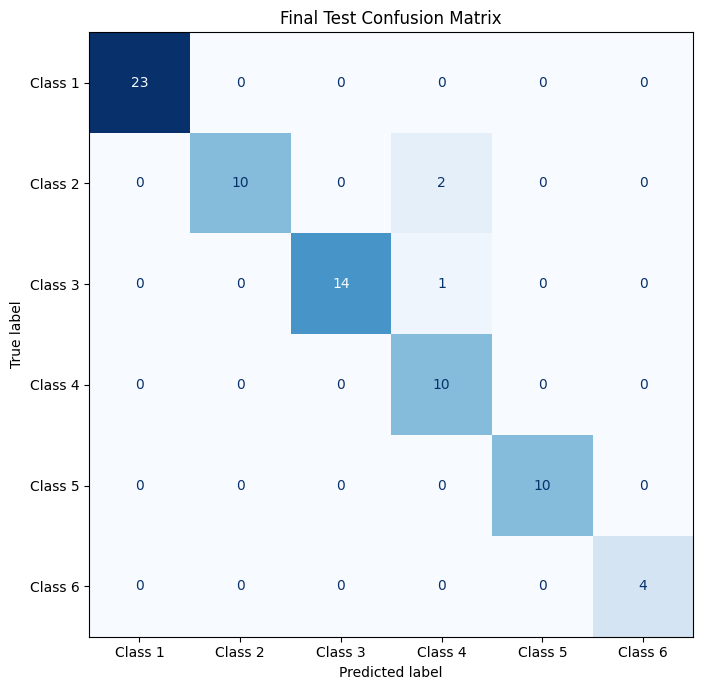

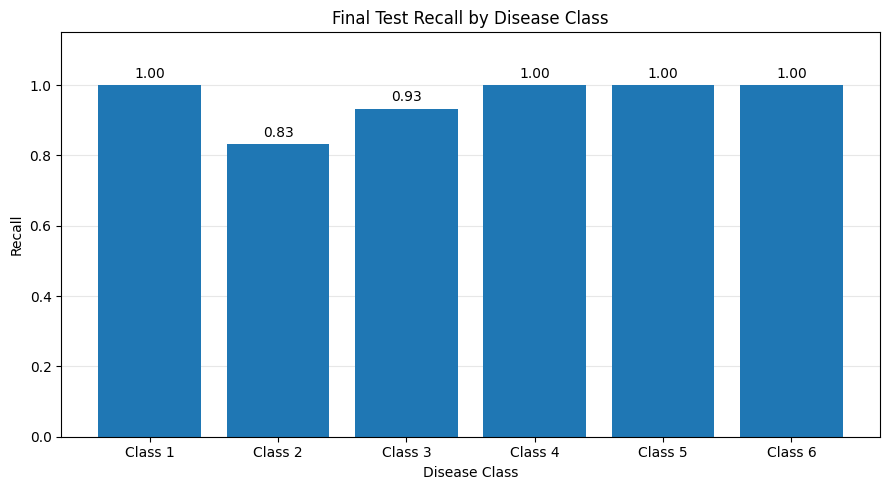

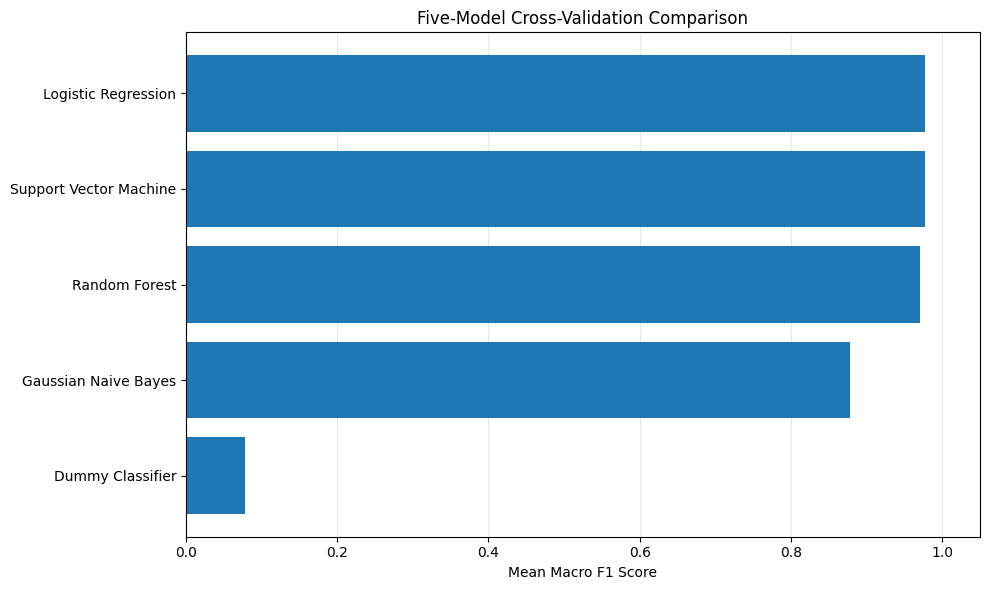

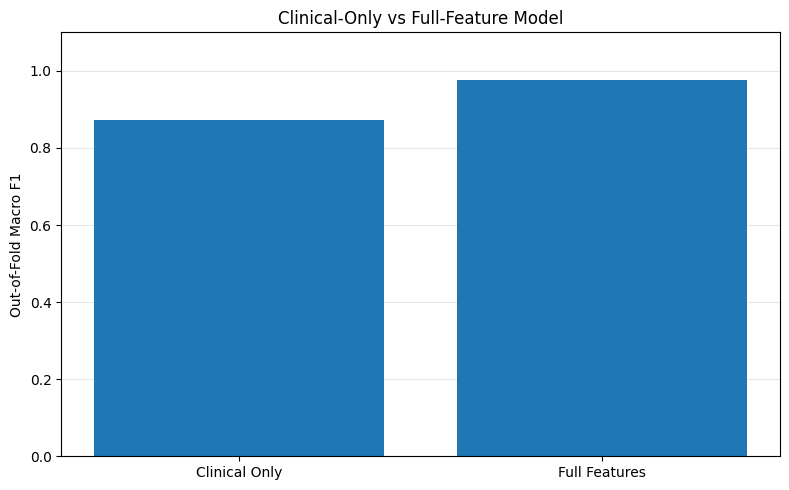


SAVED EVALUATION FIGURES
PASS - confusion_matrix.png (37.17 KB)
PASS - per_class_recall.png (28.27 KB)
PASS - model_comparison.png (37.07 KB)
PASS - clinical_vs_full.png (24.14 KB)

Cell 12 completed successfully.


In [12]:

# Cell 12 - Final Model Evaluation Visualizations
# No model training

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    recall_score
)

output_dir = Path("skin_disorder_outputs")
output_dir.mkdir(exist_ok=True)

print("FINAL PROJECT VISUALIZATIONS")
print("=" * 60)

# --------------------------------------------------
# 1. Final Test Confusion Matrix
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 7))

ConfusionMatrixDisplay(
    confusion_matrix=test_cm,
    display_labels=[f"Class {c}" for c in class_labels]
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title("Final Test Confusion Matrix")

plt.tight_layout()
plt.savefig(
    output_dir / "confusion_matrix.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# --------------------------------------------------
# 2. Disease-Wise Test Recall
# --------------------------------------------------

per_class_recall = recall_score(
    y_test,
    final_test_pred,
    labels=class_labels,
    average=None,
    zero_division=0
)

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    [f"Class {c}" for c in class_labels],
    per_class_recall
)

ax.set_title("Final Test Recall by Disease Class")
ax.set_xlabel("Disease Class")
ax.set_ylabel("Recall")
ax.set_ylim(0, 1.15)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

for bar, value in zip(bars, per_class_recall):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.2f}",
        ha="center"
    )

plt.tight_layout()
plt.savefig(
    output_dir / "per_class_recall.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# --------------------------------------------------
# 3. Cross-Validation Model Comparison
# --------------------------------------------------

plot_data = model_comparison.sort_values("Macro_F1")

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    plot_data["Model"],
    plot_data["Macro_F1"]
)

ax.set_title("Five-Model Cross-Validation Comparison")
ax.set_xlabel("Mean Macro F1 Score")
ax.set_xlim(0, 1.05)
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(
    output_dir / "model_comparison.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# --------------------------------------------------
# 4. Clinical-Only vs Full-Feature Comparison
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    clinical_comparison["Model"],
    clinical_comparison["Macro_F1"]
)

ax.set_title(
    "Clinical-Only vs Full-Feature Model"
)
ax.set_ylabel("Out-of-Fold Macro F1")
ax.set_ylim(0, 1.1)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(
    output_dir / "clinical_vs_full.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# --------------------------------------------------
# 5. Verify Saved Figures
# --------------------------------------------------

figure_files = [
    "confusion_matrix.png",
    "per_class_recall.png",
    "model_comparison.png",
    "clinical_vs_full.png"
]

print("\nSAVED EVALUATION FIGURES")
print("=" * 60)

for filename in figure_files:
    file_path = output_dir / filename

    if file_path.is_file():
        size_kb = file_path.stat().st_size / 1024
        print(f"PASS - {filename} ({size_kb:.2f} KB)")
    else:
        print(f"FAIL - {filename}")

print("\nCell 12 completed successfully.")


In [13]:

# Cell 13 - Saved Model Prediction Demonstration
# Uses existing trained model - no retraining

from pathlib import Path
import joblib
import json
import numpy as np
import pandas as pd

output_dir = Path("skin_disorder_outputs")

# Step 1: Reload the saved model
model_path = output_dir / "logistic_regression_pipeline.joblib"
metadata_path = output_dir / "model_metadata.json"

saved_model = joblib.load(model_path)

with open(metadata_path, "r", encoding="utf-8") as file:
    saved_metadata = json.load(file)

print("SAVED MODEL PREDICTION DEMONSTRATION")
print("=" * 65)

# Step 2: Select 12 existing test records
sample_X = X_test.iloc[:12].copy()
sample_y = y_test.loc[sample_X.index]

# Step 3: Verify feature order
expected_features = saved_metadata["input_features"]

assert sample_X.columns.tolist() == expected_features
assert sample_X.shape[1] == 34

# Step 4: Predict disease classes
predicted_classes = saved_model.predict(sample_X)

# Step 5: Obtain model probability estimates
class_scores = saved_model.predict_proba(sample_X)

highest_scores = class_scores.max(axis=1)

# Step 6: Identify second-ranked class
class_order = np.argsort(class_scores, axis=1)

second_class_positions = class_order[:, -2]

second_classes = saved_model.classes_[
    second_class_positions
]

# Step 7: Create demonstration table
prediction_demo = pd.DataFrame({
    "Patient_Record": sample_X.index,
    "Actual_Class": sample_y.to_numpy(),
    "Predicted_Class": predicted_classes,
    "Model_Score": highest_scores,
    "Second_Ranked_Class": second_classes,
    "Correct": (
        predicted_classes == sample_y.to_numpy()
    )
})

print("\nSAMPLE PATIENT PREDICTIONS")
print("=" * 65)

display(prediction_demo.round(4))

# Step 8: Verify predictions match existing model
assert np.array_equal(
    predicted_classes,
    final_model.predict(sample_X)
)

print("\nMODEL VERIFICATION")
print("=" * 65)

print("Saved model loaded: YES")
print("Input features:", sample_X.shape[1])
print("Disease classes:", saved_model.classes_)
print("Predictions match original model: YES")

# Step 9: Save demonstration results
prediction_path = output_dir / "prediction_demo.csv"

prediction_demo.to_csv(
    prediction_path,
    index=False
)

print("\nPREDICTION DEMONSTRATION SAVED")
print("=" * 65)

print("File:", prediction_path)
print("Number of sample records:", len(prediction_demo))

print("\nCell 13 completed successfully.")


SAVED MODEL PREDICTION DEMONSTRATION

SAMPLE PATIENT PREDICTIONS


,Patient_Record,Actual_Class,Predicted_Class,Model_Score,Second_Ranked_Class,Correct
0,35,2,2,0.9087,1,True
1,313,3,3,0.9988,5,True
2,160,4,4,0.9963,2,True
3,182,1,1,0.9386,5,True
4,218,4,4,0.9826,2,True
5,144,3,3,0.9999,4,True
6,308,4,4,0.9678,2,True
7,86,1,1,0.7655,2,True
8,286,2,2,0.9284,4,True
9,23,3,3,0.9998,1,True



MODEL VERIFICATION
Saved model loaded: YES
Input features: 34
Disease classes: [1 2 3 4 5 6]
Predictions match original model: YES

PREDICTION DEMONSTRATION SAVED
File: skin_disorder_outputs\prediction_demo.csv
Number of sample records: 12

Cell 13 completed successfully.



# Skin Disorder Prediction (PRCP-1027)
## Final Project Analysis and Conclusion

### 1. Project Objective

The objective of this project is to develop a machine
learning model for classifying six types of
erythemato-squamous skin diseases using clinical and
histopathological patient measurements.

The project also investigates whether clinical features
alone could support earlier-stage disease assessment.

The system is an educational decision-support prototype,
not a clinically validated diagnostic system.

### 2. Dataset Description

The dermatology dataset contains:

- Total patients: 366
- Input features: 34
- Target column: class
- Disease categories: 6
- Training patients: 292
- Testing patients: 74

The measurements include clinical observations, family
history, patient age, and histopathological findings.

### 3. Exploratory Data Analysis

The following observations were made:

- Missing values: 8, all in Age.
- Duplicate records: 0.
- Graded feature values were within expected ranges.
- Minimum recorded age: 0 years.
- Maximum recorded age: 75 years.
- Median age: 35 years.

Disease class distribution:

| Class | Patients |
|---|---:|
| 1 | 112 |
| 2 | 61 |
| 3 | 72 |
| 4 | 49 |
| 5 | 52 |
| 6 | 20 |

Class 6 had the fewest records, creating uncertainty
in estimates of performance for that disease.

Feature analysis highlighted differences across classes,
particularly for perifollicular parakeratosis, follicular
horn plug, follicular papules, and fibrosis of the
papillary dermis.

These were descriptive findings, not verified clinical
diagnostic rules.

### 4. Data Preprocessing

A stratified 80:20 train-test split was used.

Missing ages were handled through median imputation
inside machine learning pipelines.

StandardScaler was included for algorithms that
benefit from standardized numerical inputs.

These preprocessing steps were fitted using training
data only to reduce data leakage.

Five-fold stratified cross-validation was performed
on the 292 training patients.

### 5. Machine Learning Model Comparison

Five classification algorithms were evaluated.

| Model | CV Accuracy | CV Macro F1 |
|---|---:|---:|
| Dummy Classifier | 0.3048 | 0.0779 |
| Logistic Regression | 0.9794 | 0.9768 |
| Gaussian Naive Bayes | 0.8972 | 0.8776 |
| Random Forest | 0.9760 | 0.9704 |
| Support Vector Machine | 0.9794 | 0.9768 |

Logistic Regression and SVM produced identical
out-of-fold predictions.

Logistic Regression was selected because of its
strong performance, efficiency, and inspectable
linear coefficients.

### 6. Final Model Performance

Selected model: Logistic Regression

Final held-out test results:

- Accuracy: 95.95%
- Macro F1-score: 0.9574
- Balanced accuracy: 96.11%
- Weighted F1-score: 0.9606
- Correct predictions: 71 out of 74
- Incorrect predictions: 3

The final model misclassified:

- Two Class 2 patients as Class 4.
- One Class 3 patient as Class 4.

Class 6 had four test patients, all correctly
classified. This sample is too small to establish
reliable performance for future Class 6 patients.

### 7. Clinical-Only vs Full-Feature Analysis

A clinical-only Logistic Regression model was
evaluated using 12 features, including Age.

Training-only out-of-fold results:

| Model | Features | Accuracy | Macro F1 |
|---|---:|---:|---:|
| Clinical-only | 12 | 0.8767 | 0.8733 |
| Full-feature | 34 | 0.9795 | 0.9771 |

The clinical-only model performed less accurately
than the full-feature model.

This indicates that histopathological information
provided substantial additional predictive value
in this dataset.

The clinical-only experiment has not undergone a
separate final test or external clinical validation.

### 8. Suggestions for Doctors and Early Identification

The following suggestions describe possible future
research and clinical decision-support applications,
not instructions for automated diagnosis.

**1. Structured clinical observations**

Clinicians could use consistent recording of
erythema, scaling, itching, lesion characteristics,
family history, and patient age.

Complete, standardized data may support clearer
comparison between similar conditions.

**2. Clinical-only decision support**

The clinical-only model may justify further research
into tools that assist with preliminary differential
assessment before histopathological findings
are available.

It should not replace dermatologist assessment.

**3. Attention to overlapping disease patterns**

The models showed confusion between certain
disease classes, particularly Classes 2 and 4.

Such ambiguous cases require careful professional
assessment rather than relying on an automated label.

**4. Histopathological confirmation when indicated**

The full-feature model performed better than the
clinical-only model.

This demonstrates the value of additional
histopathological information in the dataset,
although decisions about biopsy and diagnosis
must remain with qualified clinicians.

**5. Human oversight and clinical validation**

Before practical medical use, models would need
larger and more diverse datasets, independent
clinical evaluation, calibration assessment,
and ongoing monitoring.

Predictions should be reviewed by medical
professionals and not treated as confirmed diagnoses.

### 9. Challenges Faced and Solutions

**Challenge 1: Small dataset**

Only 366 patient records were available.

Solution:
Stratified splitting and five-fold cross-validation
were used to support more reliable comparisons.

**Challenge 2: Missing patient ages**

Eight Age values were missing.

Solution:
Median imputation was performed inside preprocessing
pipelines to prevent information leakage.

**Challenge 3: Uneven disease class sizes**

Class 6 contained only 20 records.

Solution:
Stratified evaluation and Macro F1 were used
to give each disease class appropriate attention.

**Challenge 4: Similar characteristics across diseases**

Several classes shared clinical and histopathological
patterns, causing misclassifications.

Solution:
Multiple algorithms and per-class confusion matrices
were evaluated to understand these errors.

**Challenge 5: Early identification without biopsy data**

The complete model requires histopathological
measurements that may not be available at
initial clinical presentation.

Solution:
A separate clinical-only experiment was conducted
to assess the predictive value of earlier-available
information.

### 10. Limitations

The dataset is small and may not represent the
diversity of patients encountered in clinical practice.

The rarest class had only four held-out test cases.

The model's estimated class probabilities have not
been independently calibrated.

No external hospital-based validation was conducted.

A high accuracy on this dataset does not establish
diagnostic reliability, patient safety, or suitability
for clinical deployment.

### 11. Conclusion

This project demonstrated machine learning-based
classification of six erythemato-squamous skin
disease categories using clinical and
histopathological data.

Among five evaluated classifiers, Logistic Regression
was selected as the final model.

It achieved 95.95% accuracy and a Macro F1-score
of 0.9574 on the held-out test set.

The clinical-only experiment also showed potential
for future research into earlier-stage decision
support, although its performance was lower than
the full-feature model.

The results are promising for an educational
machine learning project but require substantially
more clinical validation before practical use.

### 12. Future Scope

Potential future improvements include:

- Larger, more diverse clinical datasets.
- Independent external validation.
- Additional assessment of rare disease classes.
- Probability calibration and uncertainty analysis.
- Improved clinical-only classification models.
- Clinician-guided evaluation of model explanations.
- Monitoring for data drift and performance changes.



# Cell 15 - GitHub Documentation and Final File Verification
# No model training

from pathlib import Path
from importlib.metadata import version

project_dir = Path.cwd()
output_dir = project_dir / "skin_disorder_outputs"

print("SKIN DISORDER PREDICTION - GITHUB PREPARATION")
print("=" * 65)

print("\nPROJECT FOLDER")
print(project_dir)

# --------------------------------------------------
# 1. Create README.md
# --------------------------------------------------

readme = """# Skin Disorder Prediction (PRCP-1027)

## Project Overview

This project uses machine learning to classify six
categories of erythemato-squamous skin diseases
using clinical and histopathological measurements.

The project is an educational machine learning
study, not a clinically validated diagnostic system.

## Dataset

- Patient records: 366
- Input features: 34
- Disease classes: 6
- Training records: 292
- Test records: 74
- Missing values: 8 (Age)
- Duplicate records: 0

The dataset includes clinical features, family
history, age and histopathological measurements.

## Methodology

1. Dataset loading and inspection
2. Exploratory data analysis
3. Data quality assessment
4. Stratified train-test split (80:20)
5. Median imputation for missing ages
6. Feature scaling where required
7. Five-fold stratified cross-validation
8. Model comparison and selection
9. Independent held-out test evaluation
10. Model saving and prediction demonstration

## Machine Learning Models

| Model | CV Accuracy | CV Macro F1 |
|---|---:|---:|
| Dummy Classifier | 0.3048 | 0.0779 |
| Logistic Regression | 0.9794 | 0.9768 |
| Gaussian Naive Bayes | 0.8972 | 0.8776 |
| Random Forest | 0.9760 | 0.9704 |
| Support Vector Machine | 0.9794 | 0.9768 |

## Selected Model

**Logistic Regression**

The saved model includes:
- Median imputation
- StandardScaler
- Logistic Regression classifier

### Final Held-Out Test Results

| Metric | Result |
|---|---:|
| Accuracy | 95.95% |
| Macro F1 | 0.9574 |
| Balanced Accuracy | 96.11% |
| Weighted F1 | 0.9606 |

- Correct predictions: 71 / 74
- Incorrect predictions: 3

## Evaluation Visualizations

### Confusion Matrix
![Confusion Matrix](skin_disorder_outputs/confusion_matrix.png)

### Per-Class Recall
![Per-Class Recall](skin_disorder_outputs/per_class_recall.png)

### Model Comparison
![Model Comparison](skin_disorder_outputs/model_comparison.png)

### Clinical-Only vs Full Features
![Clinical Comparison](skin_disorder_outputs/clinical_vs_full.png)

## Clinical-Only Experiment

A second experiment used 12 clinical features,
excluding biopsy-derived histopathological features.

| Configuration | Features | OOF Macro F1 |
|---|---:|---:|
| Clinical-only | 12 | 0.8733 |
| Full-feature | 34 | 0.9771 |

Histopathological features substantially improved
classification performance on this dataset.

The clinical-only experiment suggests an area for
further research, not a validated screening tool.

## How to Run

1. Install Python and Jupyter Notebook.
2. Install dependencies:

    pip install -r requirements.txt

3. Obtain the dermatology dataset from the project source.
4. Place the CSV in the notebook's folder.
5. Open the project .ipynb notebook in Jupyter.
6. Run the cells in order.

The saved pipeline can be loaded using joblib.
Provide all 34 features in the order recorded
in model_metadata.json.

Only load model files from trusted sources.

## Project Files

The skin_disorder_outputs folder contains:

- logistic_regression_pipeline.joblib
- model_metadata.json
- model_comparison.csv
- final_test_metrics.csv
- prediction_demo.csv
- confusion_matrix.png
- per_class_recall.png
- model_comparison.png
- clinical_vs_full.png

## Challenges and Solutions

- Small dataset: stratified cross-validation.
- Missing ages: median imputation in pipelines.
- Class imbalance: Macro F1 and per-class recall.
- Similar diseases: detailed confusion matrix analysis.
- Early identification: separate clinical-only experiment.

## Limitations

The dataset contains only 366 patients.
The rarest disease class has four test cases.

No external clinical validation was performed.
Model probability calibration was not evaluated.

The full model requires histopathological information.

The results do not establish suitability for
clinical diagnosis or patient treatment.

## Conclusion

Logistic Regression was selected after comparison
with four other classification algorithms.

It achieved 95.95% accuracy and 0.9574 Macro F1
on the reserved test dataset.

The model is suitable as an educational capstone
demonstration and requires extensive additional
validation before any real-world medical application.
"""

readme_path = project_dir / "README.md"

readme_path.write_text(
    readme,
    encoding="utf-8"
)

# --------------------------------------------------
# 2. Create requirements.txt
# --------------------------------------------------

packages = [
    "numpy",
    "pandas",
    "scikit-learn",
    "matplotlib",
    "joblib"
]

requirements = "\n".join(
    f"{package}=={version(package)}"
    for package in packages
) + "\n"

requirements_path = project_dir / "requirements.txt"

requirements_path.write_text(
    requirements,
    encoding="utf-8"
)

# --------------------------------------------------
# 3. Create .gitignore
# --------------------------------------------------

gitignore = """
# Jupyter checkpoint files
.ipynb_checkpoints/

# Python temporary files
__pycache__/
*.pyc

# Virtual environments
.venv/
venv/

# Local datasets
dataset_35_dermatology*.csv
data/
dataset/

# Logs
*.log
"""

gitignore_path = project_dir / ".gitignore"

gitignore_path.write_text(
    gitignore.strip() + "\n",
    encoding="utf-8"
)

# --------------------------------------------------
# 4. Verify GitHub documentation
# --------------------------------------------------

print("\nGITHUB DOCUMENTATION")
print("=" * 65)

documentation_files = [
    readme_path,
    requirements_path,
    gitignore_path
]

for file in documentation_files:
    if file.is_file() and file.stat().st_size > 0:
        print("PASS -", file.name)
    else:
        print("FAIL -", file.name)

# --------------------------------------------------
# 5. Verify saved model and results
# --------------------------------------------------

print("\nMODEL AND RESULT FILES")
print("=" * 65)

output_files = [
    "logistic_regression_pipeline.joblib",
    "model_metadata.json",
    "model_comparison.csv",
    "final_test_metrics.csv",
    "prediction_demo.csv",
    "confusion_matrix.png",
    "per_class_recall.png",
    "model_comparison.png",
    "clinical_vs_full.png"
]

for filename in output_files:
    file = output_dir / filename

    if file.is_file() and file.stat().st_size > 0:
        print("PASS -", filename)
    else:
        print("FAIL -", filename)

# --------------------------------------------------
# 6. Verify Jupyter notebook
# --------------------------------------------------

print("\nJUPYTER NOTEBOOKS")
print("=" * 65)

notebooks = sorted(project_dir.glob("*.ipynb"))

if notebooks:
    for notebook in notebooks:
        size_mb = notebook.stat().st_size / (1024 ** 2)
        print(f"{notebook.name} - {size_mb:.2f} MB")
else:
    print("FAIL - No notebook found")

# --------------------------------------------------
# 7. Final verification
# --------------------------------------------------

all_files = documentation_files + [
    output_dir / name
    for name in output_files
]

all_present = all(
    file.is_file() and file.stat().st_size > 0
    for file in all_files
)

notebook_found = any(
    notebook.stat().st_size > 1024
    for notebook in notebooks
)

print("\nFINAL VERIFICATION")
print("=" * 65)

print("Required files present:", all_present)
print("Notebook found:", notebook_found)

if all_present and notebook_found:
    print("GitHub preparation: PASSED")
else:
    print("GitHub preparation: NEEDS REVIEW")

print("\nCell 15 completed successfully.")


In [16]:

# Cell 16 - Fix Missing GitHub Files
# No model training

from pathlib import Path
from importlib.metadata import version

# Exact project folder from Cell 1
project_dir = Path(
    r"E:\datamites project\Hardest capstone 4\Skin\Skin Disease"
)

if not project_dir.is_dir():
    raise FileNotFoundError(
        f"Project folder not found: {project_dir}"
    )

print("PROJECT FOLDER")
print("=" * 60)
print(project_dir)

# --------------------------------------------------
# 1. README.md
# --------------------------------------------------

readme = """# Skin Disorder Prediction (PRCP-1027)

## Project Overview

Machine learning classification of six
erythemato-squamous skin disease categories using
clinical and histopathological patient features.

This is an educational project, not a clinically
validated diagnostic system.

## Dataset

- Total patients: 366
- Input features: 34
- Disease classes: 6
- Missing values: 8 (Age)
- Training patients: 292
- Test patients: 74

## Methodology

1. Dataset inspection and EDA
2. Data quality assessment
3. Stratified train-test splitting
4. Median imputation and feature scaling
5. Five-fold cross-validation
6. Model comparison and selection
7. Final test evaluation
8. Model export and prediction demonstration

## Model Comparison

| Model | CV Accuracy | CV Macro F1 |
|---|---:|---:|
| Dummy Classifier | 0.3048 | 0.0779 |
| Logistic Regression | 0.9794 | 0.9768 |
| Gaussian Naive Bayes | 0.8972 | 0.8776 |
| Random Forest | 0.9760 | 0.9704 |
| SVM | 0.9794 | 0.9768 |

## Selected Model

Logistic Regression with median imputation
and StandardScaler.

### Held-Out Test Results

- Accuracy: 95.95%
- Macro F1: 0.9574
- Balanced Accuracy: 96.11%
- Weighted F1: 0.9606
- Correct predictions: 71/74

## Visualizations

### Confusion Matrix
![Confusion Matrix](skin_disorder_outputs/confusion_matrix.png)

### Per-Class Recall
![Per-Class Recall](skin_disorder_outputs/per_class_recall.png)

### Model Comparison
![Model Comparison](skin_disorder_outputs/model_comparison.png)

### Clinical-Only vs Full Features
![Clinical Comparison](skin_disorder_outputs/clinical_vs_full.png)

## Clinical-Only Experiment

A 12-feature clinical-only model achieved
an out-of-fold Macro F1 of 0.8733.

The full-feature model achieved 0.9771.

This suggests that histopathological
measurements contributed additional predictive
information in this dataset.

## Installation

Install the dependencies:

    pip install -r requirements.txt

Place the dermatology dataset CSV in the project
folder and run the Jupyter Notebook cells in order.

## Saved Outputs

The skin_disorder_outputs folder contains the
trained model, metadata, evaluation reports,
prediction demonstration and visualization files.

## Challenges

- Small dataset
- Missing patient ages
- Uneven disease-class distribution
- Similar features across disease categories
- Lower clinical-only classification performance

## Limitations

The dataset contains only 366 patients.
Class 6 has only four test patients.
No external clinical validation was performed.

The model is not intended for clinical diagnosis,
treatment decisions or unsupervised medical use.

## Conclusion

Logistic Regression was selected as the final
model after evaluating five algorithms.

It achieved 95.95% accuracy and a Macro F1 of
0.9574 on the reserved test set.
"""

# --------------------------------------------------
# 2. requirements.txt
# --------------------------------------------------

packages = [
    "numpy",
    "pandas",
    "scikit-learn",
    "matplotlib",
    "joblib"
]

requirements = "\n".join(
    f"{package}=={version(package)}"
    for package in packages
) + "\n"

# --------------------------------------------------
# 3. .gitignore
# --------------------------------------------------

gitignore = """# Raw datasets
dataset_35_dermatology*.csv
data/
dataset/

# Jupyter checkpoints
.ipynb_checkpoints/

# Python cache
__pycache__/
*.pyc

# Virtual environments
.venv/
venv/

# Logs
*.log
"""

# --------------------------------------------------
# 4. Create files in the exact project folder
# --------------------------------------------------

files = {
    "README.md": readme,
    "requirements.txt": requirements,
    ".gitignore": gitignore
}

print("\nCREATING GITHUB FILES")
print("=" * 60)

for filename, content in files.items():

    file_path = project_dir / filename

    file_path.write_text(
        content,
        encoding="utf-8"
    )

    print("CREATED -", file_path.name)

# --------------------------------------------------
# 5. Verify exact paths and file sizes
# --------------------------------------------------

print("\nFINAL FILE VERIFICATION")
print("=" * 60)

all_passed = True

for filename in files:

    file_path = project_dir / filename

    passed = (
        file_path.is_file()
        and file_path.stat().st_size > 0
    )

    all_passed = all_passed and passed

    print(
        "PASS" if passed else "FAIL",
        "-",
        filename
    )

    if passed:
        print("Location:", file_path)
        print("Size:", file_path.stat().st_size, "bytes")

print("\nFINAL STATUS")
print("=" * 60)

print("All three files created:", all_passed)

print("\nCell 16 completed.")


PROJECT FOLDER
E:\datamites project\Hardest capstone 4\Skin\Skin Disease

CREATING GITHUB FILES
CREATED - README.md
CREATED - requirements.txt
CREATED - .gitignore

FINAL FILE VERIFICATION
PASS - README.md
Location: E:\datamites project\Hardest capstone 4\Skin\Skin Disease\README.md
Size: 2911 bytes
PASS - requirements.txt
Location: E:\datamites project\Hardest capstone 4\Skin\Skin Disease\requirements.txt
Size: 85 bytes
PASS - .gitignore
Location: E:\datamites project\Hardest capstone 4\Skin\Skin Disease\.gitignore
Size: 205 bytes

FINAL STATUS
All three files created: True

Cell 16 completed.
